# BMP — Phân tích kết quả thực nghiệm

**Nguồn dữ liệu:** `results/results.csv`. Notebook chỉ phân tích kết quả đã lưu,
không gọi SAT/CP/MIP solver và không thay đổi CSV đầu vào.

**Cách dùng:** chọn Python của `.venv`, chạy **Restart Kernel → Run All**.
Các bảng được xuất dưới dạng CSV và LaTeX; hình được xuất PNG 300 dpi, PDF và SVG
vào `reports/experiments/`. Tên hình và chú thích bên dưới dùng được khi viết paper.

**Câu hỏi thực nghiệm:** (1) Bao nhiêu lượt có nghiệm và chứng minh tối ưu?
(2) Bandwidth cách kết quả tham chiếu bao xa? (3) AMO ảnh hưởng thế nào trong từng
solver SAT? (4) Các baseline CP/MIP/CP-SAT đạt kết quả nào? (5) Khó khăn tăng thế nào
theo kích thước instance?

Notebook không phân nhóm theo tên máy. CSV này không đủ metadata để xác nhận một
cấu hình phần cứng thống nhất; số liệu thời gian được dùng để mô tả các lượt đã ghi nhận,
không suy ra hệ số tăng tốc được kiểm soát theo phần cứng.

## 1. Thiết lập và quy ước đánh giá

- Phạm vi: các instance Table 6 và Table 7 có `n < 400` trong tập kết quả hiện tại.
  Không thêm dòng `LIMIT` cho instance không có trong CSV; chúng nằm ngoài tập đánh giá này.
- 4 solver SAT × 3 AMO (`pairwise`, `sequential`, `product`) và 4 baseline
  (`cplex-cp`, `cplex-mip`, `gurobi`, `cp-sat`) tạo thành 16 cấu hình.
- Giới hạn cấu hình là 600 giây/lượt. `Runtime_s` là thời gian runner ghi nhận,
  có thể vượt giới hạn; không tự cắt hoặc thay bằng 600.
- `OPTIMAL`: runner ghi nhận đã chứng minh tối ưu. `TIMEOUT`: hết ngân sách nhưng
  chưa chứng minh tối ưu; vẫn có thể có nghiệm. `ERROR`: lỗi thực thi, không tính là TIMEOUT.
- `Bandwidth` nhỏ hơn là tốt hơn. Ô trống nghĩa là **không ghi nhận bandwidth**,
  không phải bandwidth bằng 0 và không chứng minh bài toán vô nghiệm.
- `Paper_Best` là giá trị tham chiếu tốt nhất trong bảng bài báo, không mặc nhiên là tối ưu.
  Chỉ khi `Paper_LB == Paper_Best`, hai cận mới xác định giá trị tối ưu tham chiếu.
- Trùng `Paper_Best` và `Status == OPTIMAL` là hai tiêu chí riêng. Nếu một lượt TIMEOUT
  trùng cả hai cận tham chiếu, notebook vẫn giữ nguyên trạng thái của runner.
- `Gap_paper (%) = 100 × (Bandwidth − Paper_Best) / Paper_Best`;
  đây là độ lệch với bài báo, **không phải** optimality gap nội bộ solver.

CSV không chứa hoán vị nghiệm hoặc chứng chỉ UNSAT. Các kiểm tra dưới đây kiểm tra tính
nhất quán của kết quả; không thay thế việc kiểm chứng nghiệm trên đồ thị.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'results' / 'results.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục BMP hoặc thư mục notebooks.')
INPUT = ROOT / 'results' / 'results.csv'
OUT = ROOT / 'reports' / 'experiments'
FIG = OUT / 'figures'
TAB = OUT / 'tables'
for folder in (OUT, FIG, TAB):
    folder.mkdir(parents=True, exist_ok=True)

SAT_SOLVERS = ['order-inc', 'order-iter', 'pairwise-inc', 'pairwise-iter']
AMOS = ['pairwise', 'sequential', 'product']
BASELINES = ['cplex-cp', 'cplex-mip', 'gurobi', 'cp-sat']
CONFIGS = [f'{s} / {a}' for s in SAT_SOLVERS for a in AMOS] + BASELINES
BASE_LABELS = {'cplex-cp': 'CPLEX CP', 'cplex-mip': 'CPLEX MIP',
               'gurobi': 'Gurobi', 'cp-sat': 'CP-SAT'}
LABELS = {c: BASE_LABELS.get(c, c) for c in CONFIGS}
AMO_COLORS = {'pairwise': '#0072B2', 'sequential': '#E69F00', 'product': '#009E73'}
STATUS_COLORS = {'OPTIMAL': '#009E73', 'TIMEOUT': '#E69F00', 'ERROR': '#CC6677'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': .18, 'axes.axisbelow': True,
    'savefig.facecolor': 'white', 'pdf.fonttype': 42, 'ps.fonttype': 42})
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 50)

CAPTIONS = {}
def savefig(fig, name, caption):
    for suffix in ['png', 'pdf', 'svg']:
        fig.savefig(FIG / f'{name}.{suffix}', dpi=300, bbox_inches='tight')
    CAPTIONS[name] = caption
    plt.show()
    plt.close(fig)

# Không phụ thuộc pandas Styler / Jinja2 để xuất LaTeX.
def latex_escape(value):
    replacements = {'\\': r'\textbackslash{}', '&': r'\&', '%': r'\%',
                    '$': r'\$', '#': r'\#', '_': r'\_', '{': r'\{',
                    '}': r'\}', '~': r'\textasciitilde{}', '^': r'\textasciicircum{}'}
    return ''.join(replacements.get(ch, ch) for ch in str(value))

def save_table(frame, name):
    frame.to_csv(TAB / f'{name}.csv', index=False, encoding='utf-8-sig', float_format='%.6g')
    lines = [r'\begin{tabular}{' + 'l' * len(frame.columns) + '}', r'\hline',
             ' & '.join(map(latex_escape, frame.columns)) + r' \\', r'\hline']
    for row in frame.itertuples(index=False, name=None):
        values = ['--' if pd.isna(v) else (f'{v:.2f}' if isinstance(v, (float, np.floating))
                  else str(v)) for v in row]
        lines.append(' & '.join(map(latex_escape, values)) + r' \\')
    lines.extend([r'\hline', r'\end{tabular}'])
    (TAB / f'{name}.tex').write_text('\n'.join(lines) + '\n', encoding='utf-8')

raw = pd.read_csv(INPUT)
df = raw.copy()
df['AMO_Method'] = df['AMO_Method'].fillna('')
df['Config'] = np.where(df['AMO_Method'].eq(''), df['Solver'],
                         df['Solver'] + ' / ' + df['AMO_Method'])
NUMERIC = ['Table', 'n', 'm', 'Paper_LB', 'Paper_Best', 'Timeout_s', 'Bandwidth',
           'Runtime_s', 'Iterations', 'Clauses', 'Vars', 'Constraints',
           'LB_Proven', 'UB_Found', 'Gap_Absolute', 'Threads']
for column in NUMERIC:
    df[column] = pd.to_numeric(df[column], errors='raise')
df['Has_BW'] = df['Bandwidth'].notna()
df['Is_Optimal'] = df['Status'].eq('OPTIMAL')
df['Match_Paper'] = df['Has_BW'] & df['Bandwidth'].eq(df['Paper_Best'])
df['Reference_Optimum_Known'] = df['Paper_LB'].eq(df['Paper_Best'])
df['Match_Known_Optimum'] = df['Match_Paper'] & df['Reference_Optimum_Known']
df['Gap_Paper_pct'] = 100 * (df['Bandwidth'] - df['Paper_Best']) / df['Paper_Best']
df['Size_Group'] = pd.cut(df['n'], bins=[0, 150, 250, 399],
                         labels=['n <= 150', '151 <= n <= 250', '251 <= n < 400'])

## 2. Kiểm tra độ đầy đủ và tính nhất quán

Notebook dừng nếu có lượt trùng, thiếu cấu hình, metadata mâu thuẫn hoặc cận không hợp lệ.
Thời gian vượt ngưỡng 605 giây được liệt kê riêng để kiểm tra overhead hoặc việc ngắt solver;
605 giây chỉ là ngưỡng cảnh báo phân tích, không thay đổi timeout thực nghiệm.

In [2]:
assert set(CONFIGS) == set(df['Config']), 'Sai tập cấu hình'
assert len(df) == 672 and df['Instance'].nunique() == 42, 'Sai kích thước tập kết quả'
assert not df.duplicated(['Instance', 'Config']).any(), 'Có lượt trùng'
assert df.groupby('Instance')['Config'].nunique().eq(16).all(), 'Thiếu cấu hình'
assert df['Status'].isin(['OPTIMAL', 'TIMEOUT', 'ERROR']).all(), 'Có trạng thái cần xử lý riêng'
required_numeric = ['Table', 'n', 'm', 'Paper_LB', 'Paper_Best', 'Timeout_s', 'Runtime_s']
assert df[required_numeric].notna().all().all(), 'Thiếu metadata bắt buộc'
assert np.isfinite(df[NUMERIC].to_numpy(dtype=float)[df[NUMERIC].notna().to_numpy()]).all()
assert df['Timeout_s'].eq(600).all() and df['n'].between(1, 399).all()
assert df['Table'].isin([6, 7]).all()
assert df['Runtime_s'].ge(0).all() and df['Paper_Best'].gt(0).all()
assert df['Paper_LB'].le(df['Paper_Best']).all()
for column in ['Table', 'n', 'm', 'Paper_LB', 'Paper_Best']:
    assert df.groupby('Instance')[column].nunique().eq(1).all(), f'Mâu thuẫn {column}'
have_bw = df.loc[df['Has_BW']]
assert have_bw['Bandwidth'].mod(1).eq(0).all()
assert have_bw['Bandwidth'].between(have_bw['Paper_LB'], have_bw['n'] - 1).all()
assert df.loc[df['Is_Optimal'], 'Has_BW'].all(), 'OPTIMAL thiếu nghiệm'
assert (df.loc[df['Is_Optimal'], 'Bandwidth'] <= df.loc[df['Is_Optimal'], 'Paper_Best']).all()
bounded = df.dropna(subset=['LB_Proven', 'UB_Found', 'Gap_Absolute'])
assert bounded['LB_Proven'].le(bounded['UB_Found']).all()
assert bounded['UB_Found'].eq(bounded['Bandwidth']).all()
assert np.allclose(bounded['UB_Found'] - bounded['LB_Proven'], bounded['Gap_Absolute'])
assert bounded.loc[bounded['Is_Optimal'], 'Gap_Absolute'].eq(0).all()

instances = df.drop_duplicates('Instance')[['Instance', 'Table', 'n', 'm',
    'Paper_LB', 'Paper_Best', 'Size_Group']].sort_values(['n', 'Instance']).reset_index(drop=True)
N = len(instances)
INSTANCE_ORDER = instances['Instance'].tolist()
status_counts = df['Status'].value_counts().reindex(['OPTIMAL', 'TIMEOUT', 'ERROR'], fill_value=0)
diagnostics = pd.DataFrame({'Check': ['Instances', 'Configurations', 'Runs', 'Numeric bandwidth',
    'Missing bandwidth', 'OPTIMAL', 'TIMEOUT', 'ERROR', 'Runtime > 605 s'],
    'Count': [N, len(CONFIGS), len(df), int(df['Has_BW'].sum()), int((~df['Has_BW']).sum()),
              *status_counts.tolist(), int(df['Runtime_s'].gt(605).sum())]})
display(diagnostics)
save_table(diagnostics, '00_data_checks')
anomalies = df.loc[df['Runtime_s'].gt(605), ['Instance', 'Config', 'Status', 'Timeout_s', 'Runtime_s']]
errors = df.loc[df['Status'].eq('ERROR'), ['Instance', 'n', 'Config', 'Status', 'Error']]
save_table(anomalies, '01_runtime_anomalies')
save_table(errors, '02_errors')
display(anomalies)
display(errors)
df.to_csv(TAB / 'analysis_rows.csv', index=False, encoding='utf-8-sig')
print('PASS: Đủ lưới 42 × 16 và các kiểm tra nhất quán. Không phải kiểm chứng hoán vị nghiệm.')

,Check,Count
0,Instances,42
1,Configurations,16
2,Runs,672
3,Numeric bandwidth,430
4,Missing bandwidth,242
5,OPTIMAL,63
6,TIMEOUT,603
7,ERROR,6
8,Runtime > 605 s,4


,Instance,Config,Status,Timeout_s,Runtime_s
258,bcsstk04,pairwise-inc / pairwise,TIMEOUT,600.0,744.922
268,bcsstk04,cplex-cp,TIMEOUT,600.0,1178.562
269,bcsstk04,cplex-mip,TIMEOUT,600.0,1046.407
351,lund_a,cp-sat,TIMEOUT,600.0,662.703


,Instance,n,Config,Status,Error
642,gre_343,343,pairwise-inc / pairwise,ERROR,MemoryError: Out of memory (OOM) during bandwi...
646,gre_343,343,pairwise-inc / sequential,ERROR,MemoryError: Out of memory (OOM) during bandwi...
647,gre_343,343,pairwise-iter / sequential,ERROR,MemoryError: Out of memory (OOM) during bandwi...
650,gre_343,343,pairwise-inc / product,ERROR,MemoryError: Out of memory (OOM) during bandwi...
651,gre_343,343,pairwise-iter / product,ERROR,MemoryError: Out of memory (OOM) during bandwi...
659,dwt_361,361,pairwise-iter / pairwise,ERROR,MemoryError: Out of memory (OOM) during bandwi...


PASS: Đủ lưới 42 × 16 và các kiểm tra nhất quán. Không phải kiểm chứng hoán vị nghiệm.


## 3. Tập dữ liệu và thiết lập thực nghiệm

Bảng metadata liệt kê toàn bộ instance, số đỉnh, số cạnh và hai giá trị tham chiếu.
Nhóm kích thước được định nghĩa theo `n`, không phải dự đoán độ khó: đồ thị nhỏ vẫn có thể TIMEOUT.

,Table,Instances,n_min,n_max,m_min,m_max
0,6,31,30,199,46,1758
1,7,11,209,361,300,1296


,Solver,AMO_Method,Runs,Timeout_s,Use_Components,Threads
0,cp-sat,,42,600.0,False,1
1,cplex-cp,,42,600.0,False,1
2,cplex-mip,,42,600.0,False,1
3,gurobi,,42,600.0,False,1
4,order-inc,pairwise,42,600.0,True,not recorded
5,order-inc,product,42,600.0,True,not recorded
6,order-inc,sequential,42,600.0,True,not recorded
7,order-iter,pairwise,42,600.0,True,not recorded
8,order-iter,product,42,600.0,True,not recorded
9,order-iter,sequential,42,600.0,True,not recorded


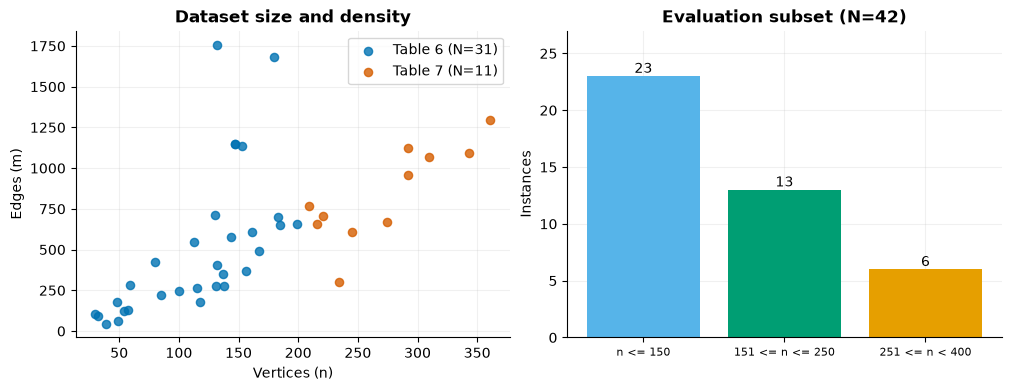

In [3]:
dataset_summary = instances.groupby('Table').agg(Instances=('Instance', 'size'),
    n_min=('n', 'min'), n_max=('n', 'max'), m_min=('m', 'min'), m_max=('m', 'max')).reset_index()
save_table(instances, '03_dataset_instances')
save_table(dataset_summary, '04_dataset_summary')
display(dataset_summary)
protocol = df.groupby(['Solver', 'AMO_Method'], dropna=False).agg(
    Runs=('Instance', 'size'), Timeout_s=('Timeout_s', 'first'),
    Use_Components=('Use_Components', lambda x: ', '.join(sorted(set(x.astype(str))))),
    Threads=('Threads', lambda x: ', '.join(str(int(v)) for v in sorted(x.dropna().unique())) or 'not recorded')
).reset_index()
save_table(protocol, '05_configuration_protocol')
display(protocol)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
for table, color in [(6, '#0072B2'), (7, '#D55E00')]:
    subset = instances[instances['Table'].eq(table)]
    axes[0].scatter(subset['n'], subset['m'], label=f'Table {table} (N={len(subset)})',
                    color=color, s=35, alpha=.8)
axes[0].set(xlabel='Vertices (n)', ylabel='Edges (m)', title='Dataset size and density')
axes[0].legend()
sizes = instances['Size_Group'].value_counts(sort=False)
bars = axes[1].bar(sizes.index.astype(str), sizes.values, color=['#56B4E9', '#009E73', '#E69F00'])
axes[1].bar_label(bars)
axes[1].set(ylabel='Instances', title=f'Evaluation subset (N={N})', ylim=(0, max(sizes) + 4))
axes[1].tick_params(axis='x', labelsize=8)
savefig(fig, '01_dataset', 'Phân bố số đỉnh và số cạnh của 42 instance; các nhóm kích thước chỉ dựa trên n.')

**Lưu ý thiết lập:** SAT bật xử lý theo thành phần liên thông, trong khi các baseline
trong CSV không bật lựa chọn này. Vì thế đây là so sánh các cấu hình triển khai hoàn chỉnh,
không cô lập riêng tác động của engine giải. `Threads` để trống nghĩa là không được ghi
trong cột này, không tự suy ra số luồng. Baseline có thể giữ nghiệm khởi tạo RCM khi hết giờ;
CSV gộp không có `Solution_Source`, nên không tách được nghiệm RCM và nghiệm do solver cải thiện.

## 4. Bảng tổng hợp và tỷ lệ hoàn thành

Các tỷ lệ dùng mẫu số 42 cho mỗi cấu hình, gồm cả lượt lỗi và thiếu nghiệm.
Median gap chỉ tính trên các lượt có bandwidth, nên luôn đọc cùng `Feasible`;
không xếp hạng bằng median gap riêng lẻ khi độ phủ nghiệm khác nhau.

,Config,Runs,Optimal,Timeout,Error,Feasible,Match_paper,Match_known_optimum,Optimal_pct,Feasible_pct,Median_gap_paper_pct,Median_runtime_optimal_s
0,order-inc / pairwise,42,3,39,0,21,5,5,7.14,50.00,15.00,40.98
1,order-inc / sequential,42,4,38,0,23,7,7,9.52,54.76,24.32,22.86
2,order-inc / product,42,4,38,0,22,7,7,9.52,52.38,20.81,32.89
3,order-iter / pairwise,42,4,38,0,24,6,6,9.52,57.14,12.50,119.17
4,order-iter / sequential,42,4,38,0,25,7,7,9.52,59.52,26.32,29.48
5,order-iter / product,42,4,38,0,23,7,7,9.52,54.76,21.43,29.34
6,pairwise-inc / pairwise,42,3,38,1,24,5,5,7.14,57.14,31.62,237.23
7,pairwise-inc / sequential,42,4,37,1,20,7,7,9.52,47.62,19.38,238.29
8,pairwise-inc / product,42,2,39,1,16,4,4,4.76,38.10,31.67,163.97
9,pairwise-iter / pairwise,42,4,37,1,24,7,7,9.52,57.14,16.88,220.49


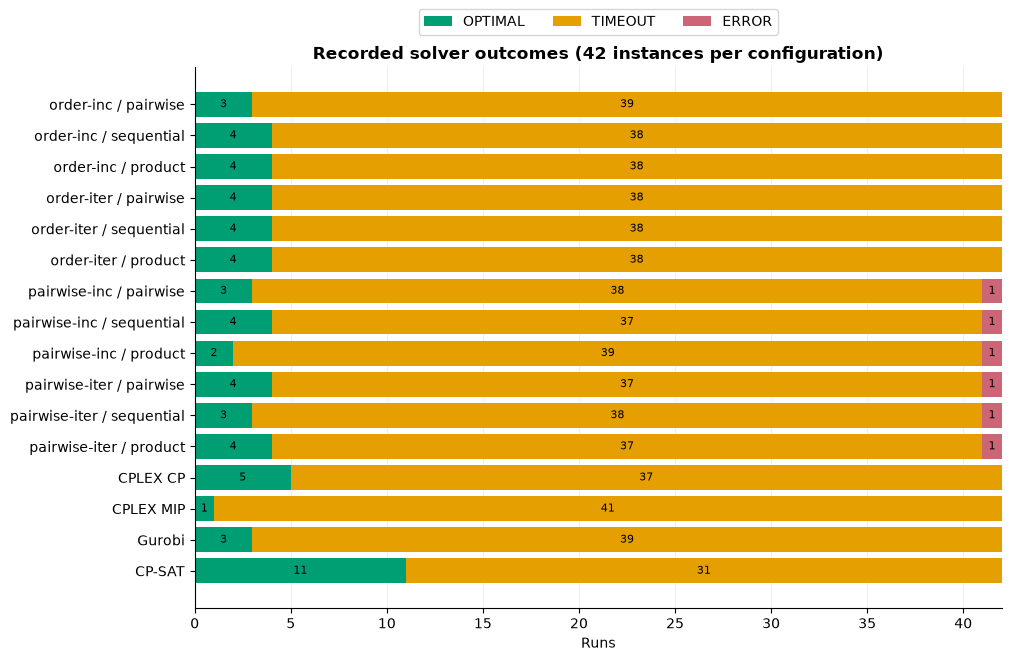

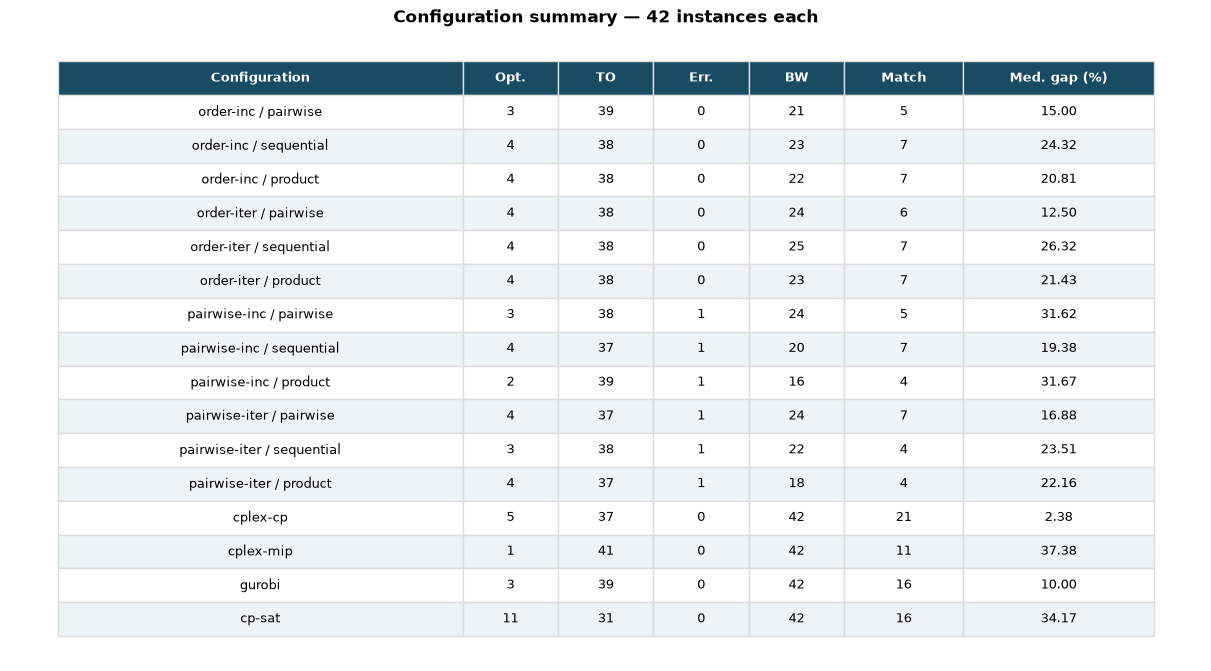

In [4]:
summary_rows = []
for cfg in CONFIGS:
    g = df[df['Config'].eq(cfg)]
    summary_rows.append({'Config': cfg, 'Runs': len(g),
        'Optimal': int(g['Is_Optimal'].sum()), 'Timeout': int(g['Status'].eq('TIMEOUT').sum()),
        'Error': int(g['Status'].eq('ERROR').sum()), 'Feasible': int(g['Has_BW'].sum()),
        'Match_paper': int(g['Match_Paper'].sum()),
        'Match_known_optimum': int(g['Match_Known_Optimum'].sum()),
        'Optimal_pct': 100 * g['Is_Optimal'].mean(), 'Feasible_pct': 100 * g['Has_BW'].mean(),
        'Median_gap_paper_pct': g['Gap_Paper_pct'].median(),
        'Median_runtime_optimal_s': g.loc[g['Is_Optimal'], 'Runtime_s'].median()})
summary = pd.DataFrame(summary_rows)
save_table(summary, '06_configuration_summary')
display(summary.round(2))

fig, ax = plt.subplots(figsize=(10, 6.5), layout='constrained')
left = np.zeros(len(summary))
for status, col in [('OPTIMAL', 'Optimal'), ('TIMEOUT', 'Timeout'), ('ERROR', 'Error')]:
    values = summary[col].to_numpy()
    ax.barh(range(len(CONFIGS)), values, left=left, color=STATUS_COLORS[status], label=status)
    for y, (start, width) in enumerate(zip(left, values)):
        if width:
            ax.text(start + width / 2, y, str(width), ha='center', va='center', fontsize=8)
    left += values
ax.set(yticks=range(len(CONFIGS)), yticklabels=[LABELS[c] for c in CONFIGS],
       xlabel='Runs', xlim=(0, N), title='Recorded solver outcomes (42 instances per configuration)')
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(.5, 1.12), ncol=3)
savefig(fig, '02_status_by_configuration', 'Trạng thái của 42 lượt trên mỗi cấu hình; ERROR được giữ riêng, TIMEOUT không đồng nghĩa không có nghiệm.')

compact = summary[['Config', 'Optimal', 'Timeout', 'Error', 'Feasible', 'Match_paper',
                   'Median_gap_paper_pct']].copy()
compact.columns = ['Configuration', 'Opt.', 'TO', 'Err.', 'BW', 'Match', 'Med. gap (%)']
compact['Med. gap (%)'] = compact['Med. gap (%)'].map(lambda v: '--' if pd.isna(v) else f'{v:.2f}')
fig, ax = plt.subplots(figsize=(12, 6.6), layout='constrained')
ax.axis('off')
tbl = ax.table(cellText=compact.values, colLabels=compact.columns, cellLoc='center',
               colWidths=[.34, .08, .08, .08, .08, .10, .16], loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.65)
for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor('#dddddd')
    if row == 0:
        cell.set_facecolor('#194b63')
        cell.set_text_props(color='white', weight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#eef3f5')
ax.set_title('Configuration summary — 42 instances each', pad=10)
savefig(fig, '03_summary_table', 'BW: số lượt ghi nhận bandwidth; Match: số lượt bằng Paper_Best. Median gap tính trên BW lượt, không tính ô thiếu.')

## 5. Chất lượng nghiệm so với bài báo

Biểu đồ độ phủ phân biệt nghiệm bằng hoặc tốt hơn tham chiếu, nghiệm kém hơn,
không có bandwidth và lỗi. Heatmap dùng ô xám cho dữ liệu thiếu; ô bằng 0% chỉ dành cho
bandwidth thực sự bằng `Paper_Best`. Mỗi hàng là một instance, sắp theo số đỉnh.

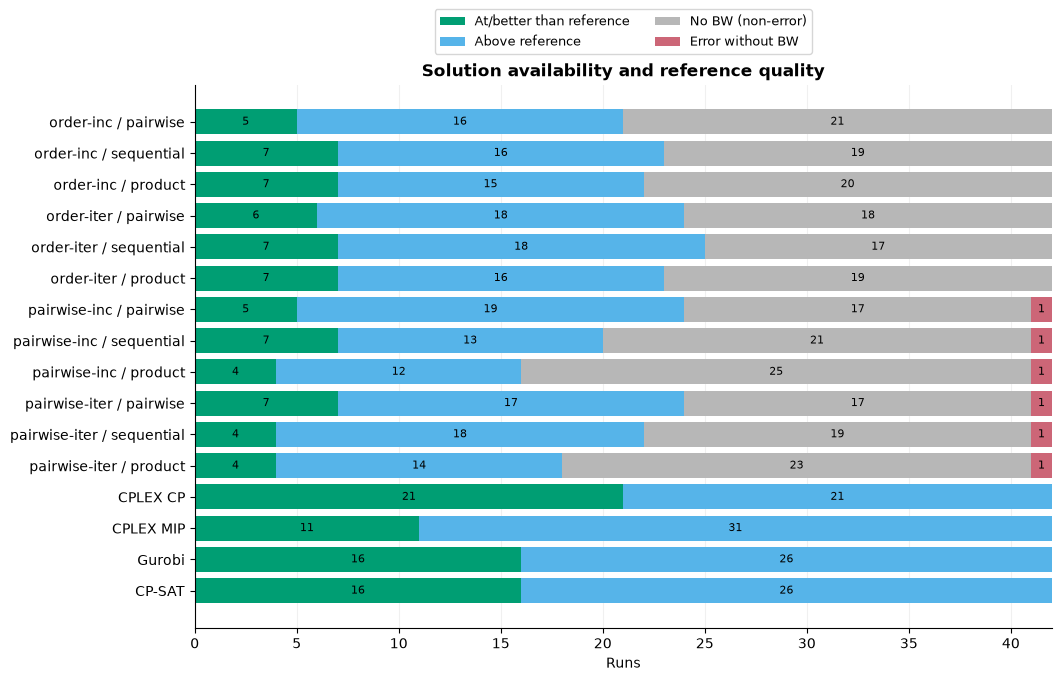

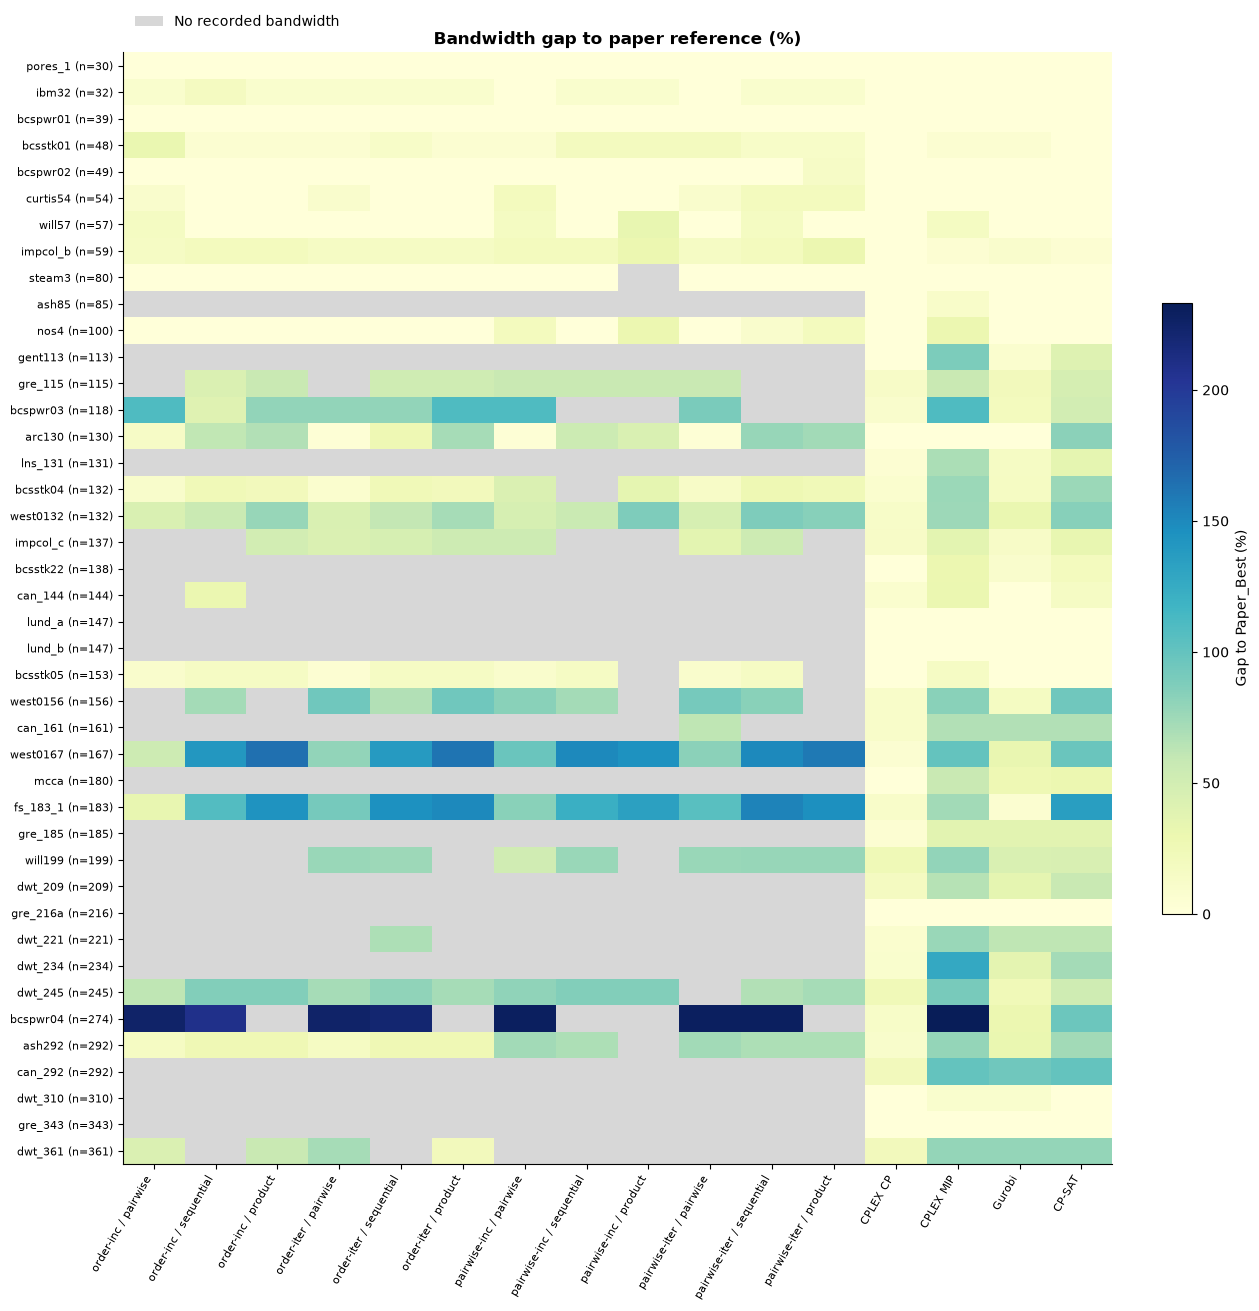

,Instance,Table,n,m,Paper_LB,Paper_Best,Size_Group,Best_observed,Configs_with_BW,Configs_optimal,Configs_match_paper,Best_gap_paper_pct
0,pores_1,6,30,103,7,7,n <= 150,7.0,16,16,16,0.000000
1,ibm32,6,32,90,11,11,n <= 150,11.0,16,1,6,0.000000
2,bcspwr01,6,39,46,5,5,n <= 150,5.0,16,15,16,0.000000
3,bcsstk01,6,48,176,16,16,n <= 150,16.0,16,2,2,0.000000
4,bcspwr02,6,49,59,7,7,n <= 150,7.0,16,1,15,0.000000
5,curtis54,6,54,124,10,10,n <= 150,10.0,16,1,10,0.000000
6,will57,6,57,127,6,6,n <= 150,6.0,16,11,11,0.000000
7,impcol_b,6,59,281,19,20,n <= 150,20.0,16,0,1,0.000000
8,steam3,6,80,424,7,7,n <= 150,7.0,15,13,15,0.000000
9,ash85,6,85,219,9,9,n <= 150,9.0,4,1,3,0.000000


In [5]:
quality = pd.DataFrame(index=CONFIGS)
quality['At/better than reference'] = df.assign(v=df['Has_BW'] & df['Bandwidth'].le(df['Paper_Best'])).groupby('Config')['v'].sum()
quality['Above reference'] = df.assign(v=df['Has_BW'] & df['Bandwidth'].gt(df['Paper_Best'])).groupby('Config')['v'].sum()
quality['No BW (non-error)'] = df.assign(v=~df['Has_BW'] & df['Status'].ne('ERROR')).groupby('Config')['v'].sum()
quality['Error without BW'] = df.assign(v=~df['Has_BW'] & df['Status'].eq('ERROR')).groupby('Config')['v'].sum()
assert quality.sum(axis=1).eq(N).all()
save_table(quality.reset_index(names='Config'), '07_quality_coverage')
fig, ax = plt.subplots(figsize=(10.5, 6.7), layout='constrained')
left = np.zeros(len(CONFIGS))
for col, color in zip(quality.columns, ['#009E73', '#56B4E9', '#b7b7b7', '#CC6677']):
    values = quality[col].to_numpy()
    ax.barh(range(len(CONFIGS)), values, left=left, label=col, color=color)
    for y, (start, width) in enumerate(zip(left, values)):
        if width:
            ax.text(start + width / 2, y, str(int(width)), ha='center', va='center', fontsize=8)
    left += values
ax.set(yticks=range(len(CONFIGS)), yticklabels=[LABELS[c] for c in CONFIGS],
       xlabel='Runs', xlim=(0, N), title='Solution availability and reference quality')
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(.5, 1.15), ncol=2, fontsize=9)
savefig(fig, '04_quality_coverage', 'Độ phủ nghiệm và quan hệ với Paper_Best; mọi cấu hình dùng cùng mẫu số 42, không loại các lượt thiếu nghiệm khỏi tỷ lệ.')

gap_matrix = df.pivot(index='Instance', columns='Config', values='Gap_Paper_pct').reindex(index=INSTANCE_ORDER, columns=CONFIGS)
save_table(gap_matrix.reset_index(), '08_gap_paper_matrix')
cmap = plt.get_cmap('YlGnBu').copy()
cmap.set_bad('#d7d7d7')
fig, ax = plt.subplots(figsize=(12.5, 13), layout='constrained')
values = np.ma.masked_invalid(gap_matrix.to_numpy(dtype=float))
im = ax.imshow(values, aspect='auto', cmap=cmap, vmin=min(0, values.min()), vmax=max(1, values.max()))
ax.set(xticks=range(len(CONFIGS)), xticklabels=[LABELS[c] for c in CONFIGS],
       yticks=range(N), yticklabels=[f'{r.Instance} (n={r.n})' for r in instances.itertuples()],
       title='Bandwidth gap to paper reference (%)')
ax.tick_params(axis='y', labelsize=8)
plt.setp(ax.get_xticklabels(), rotation=60, ha='right', fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=.55, label='Gap to Paper_Best (%)')
ax.legend(handles=[Patch(facecolor='#d7d7d7', label='No recorded bandwidth')],
          loc='upper left', bbox_to_anchor=(0, 1.045), frameon=False)
savefig(fig, '05_gap_heatmap', 'Độ lệch bandwidth so với Paper_Best trên từng instance và cấu hình. Ô xám là thiếu bandwidth, không được tính là gap 0%.')

best_by_instance = df.groupby('Instance').agg(Best_observed=('Bandwidth', 'min'),
    Configs_with_BW=('Has_BW', 'sum'), Configs_optimal=('Is_Optimal', 'sum'),
    Configs_match_paper=('Match_Paper', 'sum')).reset_index()
instance_results = instances.merge(best_by_instance, on='Instance', validate='one_to_one')
instance_results['Best_gap_paper_pct'] = 100 * (instance_results['Best_observed'] - instance_results['Paper_Best']) / instance_results['Paper_Best']
save_table(instance_results, '09_best_by_instance')
display(instance_results)

## 6. Thời gian chứng minh tối ưu — cactus plot

Đường bậc thang đếm số instance có trạng thái OPTIMAL và thời gian ghi nhận không quá `t`.
TIMEOUT/ERROR không được coi là đã giải tối ưu ở giây 600. Hai panel dùng cùng trục.
Đây là phân bố thời gian của các lượt đã ghi nhận, không phải speedup được chuẩn hóa.
Không so trực tiếp `Runtime_s` với thời gian DRSA tìm nghiệm tốt nhất trong bài báo:
điều kiện dừng và mục tiêu đo khác nhau.

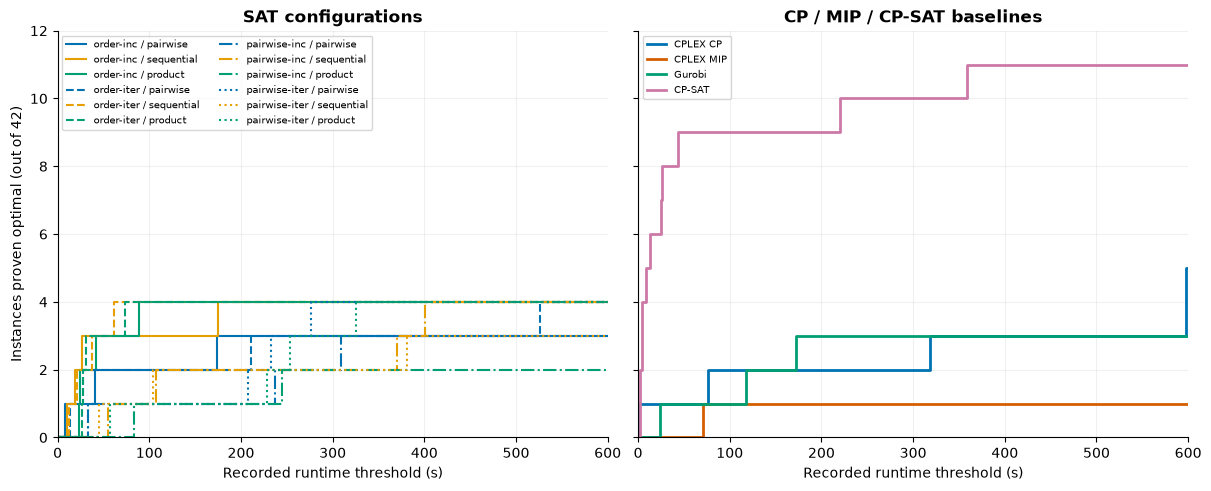

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True, layout='constrained')
linestyles = ['-', '--', '-.', ':']
max_solved = int(summary['Optimal'].max())
for s_idx, solver in enumerate(SAT_SOLVERS):
    for amo in AMOS:
        cfg = f'{solver} / {amo}'
        times = np.sort(df.loc[df['Config'].eq(cfg) & df['Is_Optimal'] & df['Runtime_s'].le(600), 'Runtime_s'])
        axes[0].step(np.r_[0, times, 600], np.r_[0, np.arange(1, len(times)+1), len(times)],
                     where='post', label=cfg, color=AMO_COLORS[amo], linestyle=linestyles[s_idx])
for solver, color in zip(BASELINES, ['#0072B2', '#D55E00', '#009E73', '#CC79A7']):
    times = np.sort(df.loc[df['Config'].eq(solver) & df['Is_Optimal'] & df['Runtime_s'].le(600), 'Runtime_s'])
    axes[1].step(np.r_[0, times, 600], np.r_[0, np.arange(1, len(times)+1), len(times)],
                 where='post', label=LABELS[solver], color=color, linewidth=2)
for ax, title in zip(axes, ['SAT configurations', 'CP / MIP / CP-SAT baselines']):
    ax.set(xlabel='Recorded runtime threshold (s)', title=title, xlim=(0, 600), ylim=(0, max_solved + 1))
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.legend(loc='upper left', fontsize=7, ncol=2 if ax is axes[0] else 1)
axes[0].set_ylabel('Instances proven optimal (out of 42)')
savefig(fig, '06_optimal_cactus', 'Số instance có trạng thái OPTIMAL theo ngưỡng thời gian ghi nhận; TIMEOUT và ERROR không tạo điểm giải thành công.')

## 7. Ảnh hưởng của AMO trong từng solver SAT

Panel thứ nhất so sánh số lượt OPTIMAL trên toàn bộ 42 instance. Panel thứ hai
chỉ so chất lượng trên **giao các instance có bandwidth ở cả ba AMO** trong cùng solver.
`k` là kích thước giao, có thể khác giữa các solver. Đây là thống kê có điều kiện trên
các instance có nghiệm ở cả ba; cần đọc cùng độ phủ trong phần 5 để tránh thiên lệch chọn mẫu.

,Solver,AMO,Common_instances,Mean_gap_paper_pct,Median_gap_paper_pct
0,order-inc,pairwise,19,22.89,14.29
1,order-inc,sequential,19,31.68,18.18
2,order-inc,product,19,37.73,15.00
3,order-iter,pairwise,21,27.45,9.09
4,order-iter,sequential,21,35.53,15.00
5,order-iter,product,21,41.79,15.00
6,pairwise-inc,pairwise,15,30.06,20.00
7,pairwise-inc,sequential,15,38.13,18.75
8,pairwise-inc,product,15,44.85,30.00
9,pairwise-iter,pairwise,17,26.17,10.00


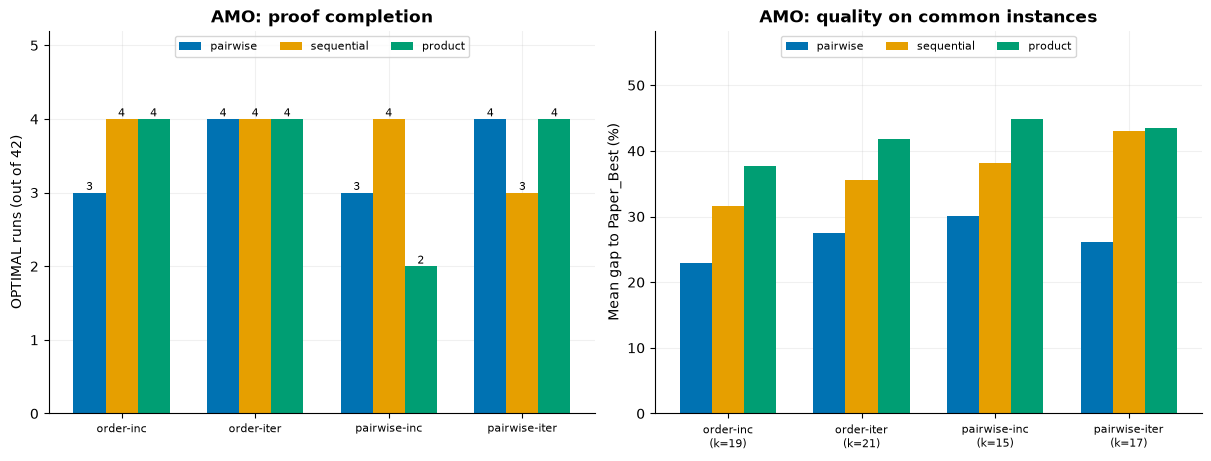

In [7]:
paired_rows = []
for solver in SAT_SOLVERS:
    wide = df[df['Solver'].eq(solver)].pivot(index='Instance', columns='AMO_Method', values='Gap_Paper_pct').reindex(columns=AMOS)
    common = wide.dropna()
    for amo in AMOS:
        paired_rows.append({'Solver': solver, 'AMO': amo, 'Common_instances': len(common),
                            'Mean_gap_paper_pct': common[amo].mean(),
                            'Median_gap_paper_pct': common[amo].median()})
paired = pd.DataFrame(paired_rows)
save_table(paired, '10_amo_common_instances')
display(paired.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
x = np.arange(len(SAT_SOLVERS))
width = .24
for j, amo in enumerate(AMOS):
    opt = [int(summary.set_index('Config').loc[f'{s} / {amo}', 'Optimal']) for s in SAT_SOLVERS]
    gaps = paired[paired['AMO'].eq(amo)].set_index('Solver').reindex(SAT_SOLVERS)['Mean_gap_paper_pct']
    b = axes[0].bar(x + (j-1)*width, opt, width, label=amo, color=AMO_COLORS[amo])
    axes[0].bar_label(b, fontsize=8)
    axes[1].bar(x + (j-1)*width, gaps, width, label=amo, color=AMO_COLORS[amo])
axes[0].set(xticks=x, xticklabels=SAT_SOLVERS, ylabel='OPTIMAL runs (out of 42)', title='AMO: proof completion')
ks = paired.groupby('Solver')['Common_instances'].first()
axes[1].set(xticks=x, xticklabels=[f'{s}\n(k={ks[s]})' for s in SAT_SOLVERS],
            ylabel='Mean gap to Paper_Best (%)', title='AMO: quality on common instances')
for ax in axes:
    ax.tick_params(axis='x', labelsize=8)
    ax.margins(y=.30)
    ax.legend(fontsize=8, loc='upper center', ncol=3)
savefig(fig, '07_amo_comparison', 'So sánh ba AMO trong từng solver SAT: số lượt OPTIMAL trên 42 instance và mean gap trên giao k instance có bandwidth ở cả ba AMO.')

## 8. Kích thước encoding và giới hạn bộ nhớ

`Clauses` và `Vars` là số liệu được lưu ở trạng thái/progress cuối cùng mà runner nhận được.
Với incremental/iterative và xử lý theo component, cách tích lũy có thể khác nhau.
Chúng không đo RAM đỉnh, không đảm bảo là CNF hoàn chỉnh tại thời điểm timeout.
Chỉ vẽ các snapshot SAT có giá trị dương, công bố số điểm được dùng; không so `Clauses`
của SAT với `Constraints` của MIP như cùng một đại lượng. Các lỗi được liệt kê đúng theo
cột `Error`; không suy ra dung lượng RAM cần thiết từ số mệnh đề.

,Solver,AMO_Method,Rows,Clause_snapshots,Positive_clause_snapshots,Median_clauses,Max_clauses,Median_vars,Errors
0,order-inc,pairwise,42,42,21,1821206.0,56196721.0,27732.0,0
1,order-inc,product,42,42,22,475815.5,10929900.0,32161.5,0
2,order-inc,sequential,42,42,23,528680.0,10908428.0,55351.0,0
3,order-iter,pairwise,42,42,24,2459777.0,49177585.0,34193.0,0
4,order-iter,product,42,42,23,215357.0,3066521.0,32922.0,0
5,order-iter,sequential,42,42,25,302068.0,1872572.0,67210.0,0
6,pairwise-inc,pairwise,42,41,24,5985178.5,114949380.0,15441.0,1
7,pairwise-inc,product,42,41,16,1945409.5,146947512.0,9691.5,1
8,pairwise-inc,sequential,42,41,20,5826841.5,129036736.0,34625.5,1
9,pairwise-iter,pairwise,42,41,24,4260257.0,88827592.0,15412.0,1


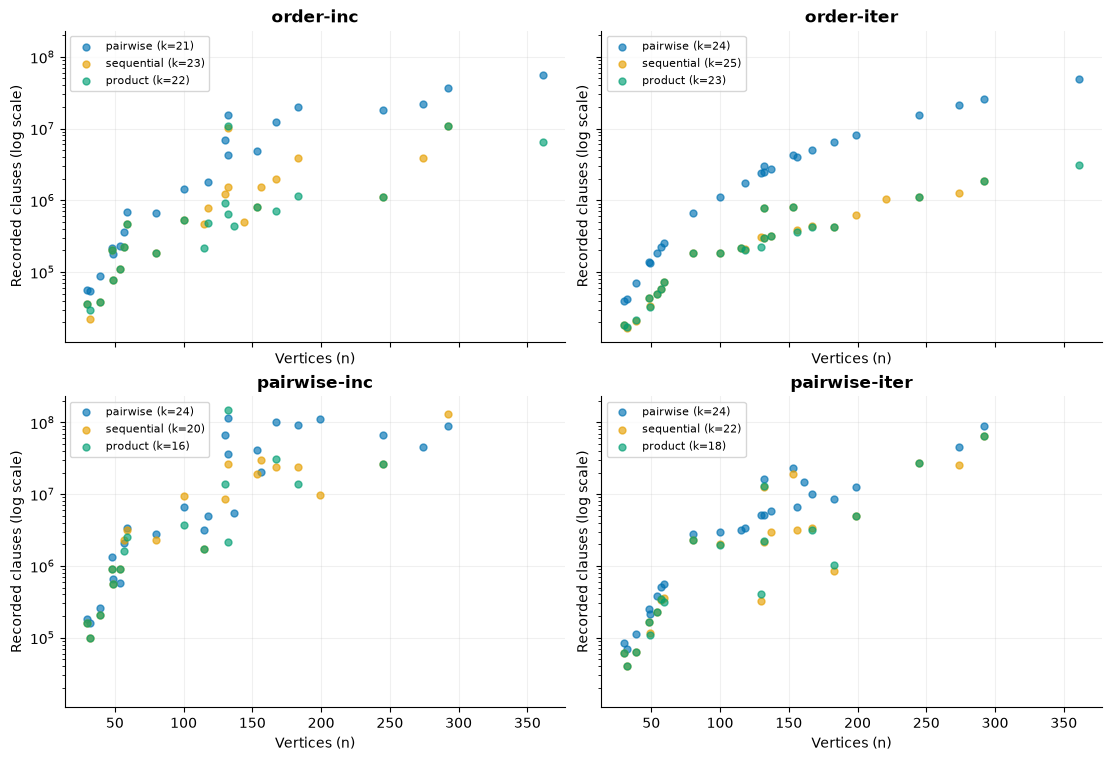

In [8]:
sat = df[df['Solver'].isin(SAT_SOLVERS)].copy()
encoding = sat.groupby(['Solver', 'AMO_Method']).agg(
    Rows=('Instance', 'size'), Clause_snapshots=('Clauses', 'count'),
    Positive_clause_snapshots=('Clauses', lambda v: int(v.gt(0).sum())),
    Median_clauses=('Clauses', lambda v: v[v.gt(0)].median()),
    Max_clauses=('Clauses', 'max'), Median_vars=('Vars', lambda v: v[v.gt(0)].median()),
    Errors=('Status', lambda v: int(v.eq('ERROR').sum()))).reset_index()
save_table(encoding, '11_encoding_snapshots')
display(encoding)
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True, layout='constrained')
for ax, solver in zip(axes.flat, SAT_SOLVERS):
    for amo in AMOS:
        part = sat[sat['Solver'].eq(solver) & sat['AMO_Method'].eq(amo) & sat['Clauses'].gt(0)]
        ax.scatter(part['n'], part['Clauses'], s=25, alpha=.65, color=AMO_COLORS[amo],
                   label=f'{amo} (k={len(part)})')
    ax.set(title=solver, yscale='log', xlabel='Vertices (n)', ylabel='Recorded clauses (log scale)')
    ax.legend(fontsize=8)
savefig(fig, '08_encoding_clauses', 'Số mệnh đề SAT ghi nhận theo n, chỉ tính snapshot dương; k là số snapshot. Không phải phép đo RAM hoặc kích thước encoding tối đa.')

## 9. Cận chứng minh của các baseline

`UB_Found` là bandwidth khả thi đã lưu; `LB_Proven` là cận dưới runner ghi nhận.
`Gap_Absolute = UB_Found − LB_Proven`, khác với `Gap_Paper_pct`.
Đồ thị có cận bằng nhau có thể xác nhận tối ưu theo runner. Không thay LB của solver
bằng `Paper_LB` để đổi nhãn TIMEOUT thành OPTIMAL.

,Solver,Runs,With_bounds,Closed_gap,Median_absolute_gap,Max_absolute_gap
0,cplex-cp,42,42,5,6.0,40.0
1,cplex-mip,42,42,1,13.0,75.0
2,gurobi,42,42,3,11.0,52.0
3,cp-sat,42,42,11,12.5,89.0


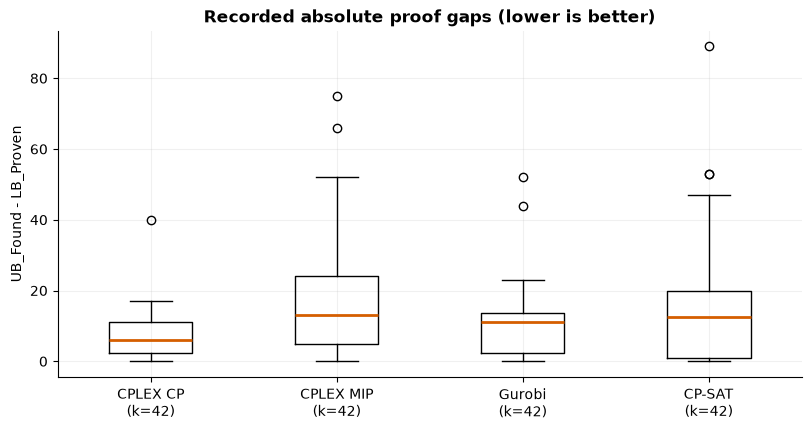

In [9]:
baseline_rows = df[df['Solver'].isin(BASELINES)].copy()
baseline_bounds = baseline_rows.groupby('Solver').agg(
    Runs=('Instance', 'size'), With_bounds=('Gap_Absolute', 'count'),
    Closed_gap=('Gap_Absolute', lambda v: int(v.eq(0).sum())),
    Median_absolute_gap=('Gap_Absolute', 'median'), Max_absolute_gap=('Gap_Absolute', 'max')
).reindex(BASELINES).reset_index()
save_table(baseline_bounds, '12_baseline_bounds_summary')
save_table(baseline_rows[['Instance', 'Config', 'Status', 'Bandwidth', 'Paper_LB',
    'Paper_Best', 'LB_Proven', 'UB_Found', 'Gap_Absolute']], '13_baseline_bounds_detail')
display(baseline_bounds)
fig, ax = plt.subplots(figsize=(8, 4.2), layout='constrained')
bound_arrays = [baseline_rows.loc[baseline_rows['Solver'].eq(s), 'Gap_Absolute'].dropna().to_numpy() for s in BASELINES]
ax.boxplot(bound_arrays, tick_labels=[f'{LABELS[s]}\n(k={len(a)})' for s, a in zip(BASELINES, bound_arrays)],
           showfliers=True, medianprops={'color': '#D55E00', 'linewidth': 2})
ax.set(ylabel='UB_Found - LB_Proven', title='Recorded absolute proof gaps (lower is better)')
savefig(fig, '09_baseline_proof_gap', 'Phân bố chênh lệch UB_Found − LB_Proven của các baseline; giá trị 0 là cận đã khép, không phải chỉ trùng Paper_Best.')

## 10. Kết quả theo kích thước và bảng chi tiết

Tỷ lệ dưới đây có mẫu số bằng số instance trong từng nhóm, trên từng cấu hình.
Không kết luận độ khó chỉ từ n; số cạnh, cấu trúc đồ thị và chất lượng cận cũng ảnh hưởng.
Bảng chi tiết bandwidth, trạng thái và thời gian được xuất riêng cho phụ lục.

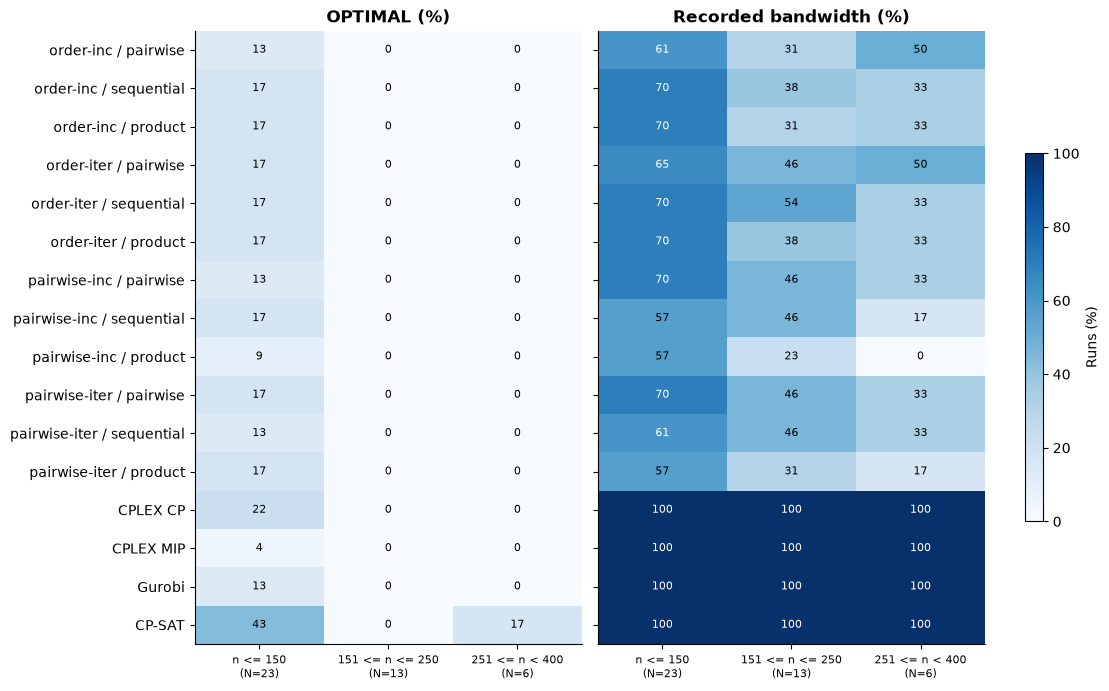

In [10]:
size_summary = df.groupby(['Config', 'Size_Group'], observed=True).agg(
    Runs=('Instance', 'size'), Optimal=('Is_Optimal', 'sum'), Feasible=('Has_BW', 'sum'),
    Match_paper=('Match_Paper', 'sum'), Errors=('Status', lambda v: int(v.eq('ERROR').sum()))).reset_index()
size_summary['Optimal_pct'] = 100 * size_summary['Optimal'] / size_summary['Runs']
size_summary['Feasible_pct'] = 100 * size_summary['Feasible'] / size_summary['Runs']
save_table(size_summary, '14_size_group_summary')
groups = list(df['Size_Group'].cat.categories)
fig, axes = plt.subplots(1, 2, figsize=(11, 6.8), sharey=True, layout='constrained')
for ax, metric, title in zip(axes, ['Optimal_pct', 'Feasible_pct'], ['OPTIMAL (%)', 'Recorded bandwidth (%)']):
    matrix = size_summary.pivot(index='Config', columns='Size_Group', values=metric).reindex(index=CONFIGS, columns=groups)
    im = ax.imshow(matrix, aspect='auto', vmin=0, vmax=100, cmap='Blues')
    for i in range(len(CONFIGS)):
        for j in range(len(groups)):
            value = matrix.iloc[i, j]
            ax.text(j, i, f'{value:.0f}', ha='center', va='center', fontsize=8,
                    color='white' if value > 60 else 'black')
    ax.set(xticks=range(len(groups)), xticklabels=[f'{g}\n(N={sizes[g]})' for g in groups],
           yticks=range(len(CONFIGS)), yticklabels=[LABELS[c] for c in CONFIGS], title=title)
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=.6, label='Runs (%)')
savefig(fig, '10_size_group_outcomes', 'Tỷ lệ OPTIMAL và tỷ lệ ghi nhận bandwidth theo nhóm n; mẫu số N của từng nhóm được ghi trên trục.')

for metric, filename in [('Bandwidth', '15_bandwidth_matrix'), ('Status', '16_status_matrix'),
                          ('Runtime_s', '17_runtime_matrix')]:
    matrix = df.pivot(index='Instance', columns='Config', values=metric).reindex(index=INSTANCE_ORDER, columns=CONFIGS)
    save_table(matrix.reset_index(), filename)
save_table(df.loc[df['Status'].eq('TIMEOUT') & df['Match_Known_Optimum'],
    ['Instance', 'Config', 'Bandwidth', 'Paper_LB', 'Paper_Best', 'Status']],
    '18_timeout_matching_known_optimum')

## 11. Nhận xét tự động và giới hạn diễn giải

Đoạn nhận xét được tính trực tiếp từ CSV. Có thể dùng làm bản nháp cho phần Thực nghiệm,
nhưng cần đối chiếu định nghĩa đồ thị và cách xây dựng mô hình trước khi kết luận về thuật toán.
Không tự thêm đặc tả phần cứng hoặc số lần lặp chưa có trong dữ liệu.

In [11]:
best_opt = summary.loc[summary['Optimal'].eq(summary['Optimal'].max())]
best_match = summary.loc[summary['Match_paper'].eq(summary['Match_paper'].max())]
best_bw = instance_results['Best_observed']
reference_best = instance_results['Paper_Best']
instances_match = int(best_bw.eq(reference_best).sum())
instances_proven = int(instance_results['Configs_optimal'].gt(0).sum())
timeout_known = int((df['Status'].eq('TIMEOUT') & df['Match_Known_Optimum']).sum())
oom_count = int(errors['Error'].fillna('').str.contains('MemoryError|OOM', case=False, regex=True).sum())
best_opt_names = ', '.join(best_opt['Config'])
best_match_names = ', '.join(best_match['Config'])
report = f'''# Bản nháp nhận xét thực nghiệm

Tập đánh giá gồm {N} instance có n < 400 trong Table 6 và Table 7, với 16 cấu hình
(12 SAT và 4 baseline), tổng cộng {len(df)} lượt. Giới hạn đặt cho mỗi lượt là 600 giây.

Kết quả ghi nhận {status_counts['OPTIMAL']} lượt OPTIMAL, {status_counts['TIMEOUT']} lượt TIMEOUT
và {status_counts['ERROR']} lượt ERROR. Có {int(df['Has_BW'].sum())}/{len(df)} lượt ghi nhận
bandwidth; {int((~df['Has_BW']).sum())} lượt còn lại không được gán bandwidth bằng 0.
Trong các lỗi, {oom_count} mô tả lỗi có chứa MemoryError/OOM; đây là phân loại từ log,
không phải phép đo độc lập về bộ nhớ.

Cấu hình có nhiều lượt chứng minh tối ưu nhất là {best_opt_names}, với
{int(best_opt['Optimal'].iloc[0])}/{N} instance. Cấu hình có nhiều lượt trùng Paper_Best nhất
là {best_match_names}, với {int(best_match['Match_paper'].iloc[0])}/{N} instance.
Hai tiêu chí này đo hai khía cạnh khác nhau; không mặc định cấu hình tốt nhất theo một
tiêu chí sẽ tốt nhất theo mọi tiêu chí.

Nếu lấy bandwidth tốt nhất trong 16 cấu hình cho mỗi instance, có {instances_match}/{N}
instance bằng Paper_Best. Đây là kết quả tổng hợp của cả tập cấu hình, không phải kết quả
của một thuật toán trong một lượt 600 giây. Có {instances_proven}/{N} instance được ít nhất
một cấu hình ghi nhận OPTIMAL.

Có {timeout_known} lượt TIMEOUT đạt bandwidth bằng cả Paper_LB và Paper_Best.
Notebook giữ nguyên trạng thái TIMEOUT: trùng giá trị tối ưu tham chiếu không đồng nghĩa
runner đã hoàn tất chứng minh tối ưu. Việc dùng các cận tham chiếu còn phụ thuộc cùng
định nghĩa và dữ liệu đồ thị.

Có {len(anomalies)} lượt có Runtime_s > 605 giây; các thời gian gốc được giữ trong bảng
01_runtime_anomalies. Biểu đồ cactus chỉ đếm OPTIMAL; không tính TIMEOUT như giải xong ở 600 giây.

## Giới hạn

- Mỗi cặp instance–cấu hình chỉ có một kết quả trong CSV, chưa có các lần lặp độc lập
  để ước lượng biến thiên giữa các lần chạy. Không báo độ lệch chuẩn của lần lặp hoặc
  kết luận ý nghĩa thống kê từ dữ liệu này.
- CSV không chứa hoán vị nghiệm, chứng chỉ UNSAT, RAM đỉnh hoặc thời điểm tìm nghiệm
  tốt nhất. Không thể kiểm chứng lại tất cả nghiệm hay kết luận về RAM chỉ từ bảng này.
- Chỉ đánh giá 42 instance đã chọn; không ngoại suy độ phủ tới toàn bộ Harwell–Boeing.
- SAT bật Use_Components, các baseline không bật; so sánh phản ánh cấu hình triển khai
  hoàn chỉnh. Nghiệm baseline có thể là RCM dự phòng, không nhất thiết do engine tìm mới.
- Thời gian chỉ mô tả lượt chạy đã ghi nhận. CSV không đủ metadata để xác nhận điều kiện
  phần cứng thống nhất; không suy ra speedup được kiểm soát hoặc so thời gian trực tiếp
  với DRSA có điều kiện dừng khác.
- Median/mean gap trên lượt có bandwidth chịu ảnh hưởng của độ phủ nghiệm. Phân tích
  AMO trên giao instance làm rõ mẫu so sánh, nhưng không loại bỏ thiên lệch do chỉ lấy
  các instance có nghiệm ở cả ba AMO.
'''
(OUT / 'experimental_findings.md').write_text(report, encoding='utf-8')
display(Markdown(report))

# Bản nháp nhận xét thực nghiệm

Tập đánh giá gồm 42 instance có n < 400 trong Table 6 và Table 7, với 16 cấu hình
(12 SAT và 4 baseline), tổng cộng 672 lượt. Giới hạn đặt cho mỗi lượt là 600 giây.

Kết quả ghi nhận 63 lượt OPTIMAL, 603 lượt TIMEOUT
và 6 lượt ERROR. Có 430/672 lượt ghi nhận
bandwidth; 242 lượt còn lại không được gán bandwidth bằng 0.
Trong các lỗi, 6 mô tả lỗi có chứa MemoryError/OOM; đây là phân loại từ log,
không phải phép đo độc lập về bộ nhớ.

Cấu hình có nhiều lượt chứng minh tối ưu nhất là cp-sat, với
11/42 instance. Cấu hình có nhiều lượt trùng Paper_Best nhất
là cplex-cp, với 21/42 instance.
Hai tiêu chí này đo hai khía cạnh khác nhau; không mặc định cấu hình tốt nhất theo một
tiêu chí sẽ tốt nhất theo mọi tiêu chí.

Nếu lấy bandwidth tốt nhất trong 16 cấu hình cho mỗi instance, có 22/42
instance bằng Paper_Best. Đây là kết quả tổng hợp của cả tập cấu hình, không phải kết quả
của một thuật toán trong một lượt 600 giây. Có 11/42 instance được ít nhất
một cấu hình ghi nhận OPTIMAL.

Có 47 lượt TIMEOUT đạt bandwidth bằng cả Paper_LB và Paper_Best.
Notebook giữ nguyên trạng thái TIMEOUT: trùng giá trị tối ưu tham chiếu không đồng nghĩa
runner đã hoàn tất chứng minh tối ưu. Việc dùng các cận tham chiếu còn phụ thuộc cùng
định nghĩa và dữ liệu đồ thị.

Có 4 lượt có Runtime_s > 605 giây; các thời gian gốc được giữ trong bảng
01_runtime_anomalies. Biểu đồ cactus chỉ đếm OPTIMAL; không tính TIMEOUT như giải xong ở 600 giây.

## Giới hạn

- Mỗi cặp instance–cấu hình chỉ có một kết quả trong CSV, chưa có các lần lặp độc lập
  để ước lượng biến thiên giữa các lần chạy. Không báo độ lệch chuẩn của lần lặp hoặc
  kết luận ý nghĩa thống kê từ dữ liệu này.
- CSV không chứa hoán vị nghiệm, chứng chỉ UNSAT, RAM đỉnh hoặc thời điểm tìm nghiệm
  tốt nhất. Không thể kiểm chứng lại tất cả nghiệm hay kết luận về RAM chỉ từ bảng này.
- Chỉ đánh giá 42 instance đã chọn; không ngoại suy độ phủ tới toàn bộ Harwell–Boeing.
- SAT bật Use_Components, các baseline không bật; so sánh phản ánh cấu hình triển khai
  hoàn chỉnh. Nghiệm baseline có thể là RCM dự phòng, không nhất thiết do engine tìm mới.
- Thời gian chỉ mô tả lượt chạy đã ghi nhận. CSV không đủ metadata để xác nhận điều kiện
  phần cứng thống nhất; không suy ra speedup được kiểm soát hoặc so thời gian trực tiếp
  với DRSA có điều kiện dừng khác.
- Median/mean gap trên lượt có bandwidth chịu ảnh hưởng của độ phủ nghiệm. Phân tích
  AMO trên giao instance làm rõ mẫu so sánh, nhưng không loại bỏ thiên lệch do chỉ lấy
  các instance có nghiệm ở cả ba AMO.


## 12. Xuất danh mục hình, chú thích và thông tin tái lập phân tích

`analysis_manifest.json` ghi SHA-256 của CSV và phiên bản thư viện **dùng để phân tích**,
không phải môi trường chạy solver. Tên file xuất cố định nên chạy lại notebook sẽ cập nhật
các sản phẩm phân tích tương ứng. CSV gốc và các checkpoint được giữ nguyên.

Gợi ý chèn vào paper: bảng `06_configuration_summary`, hình `02_status_by_configuration`,
`04_quality_coverage`, `06_optimal_cactus`, `07_amo_comparison`. Các bảng ma trận đầy đủ
và heatmap có thể chuyển sang phụ lục. Khi chèn LaTeX, dùng `\input{...}` trong `table`
hoặc `table*`; bảng 16 cấu hình có thể cần trang ngang. Các bảng `.tex` chứa dữ liệu,
chưa áp đặt template tạp chí.

In [12]:
captions_text = '# Danh mục hình và chú thích\n\n' + '\n\n'.join(
    f'## {name}\n\n{caption}\n\n[PNG](figures/{name}.png) · [PDF](figures/{name}.pdf) · [SVG](figures/{name}.svg)'
    for name, caption in CAPTIONS.items())
(OUT / 'figure_captions.md').write_text(captions_text + '\n', encoding='utf-8')
manifest = {'input': 'results/results.csv',
    'input_sha256': hashlib.sha256(INPUT.read_bytes()).hexdigest(),
    'rows': len(df), 'instances': N, 'configurations': CONFIGS,
    'statuses': {key: int(value) for key, value in status_counts.items()},
    'analysis_versions': {'python': platform.python_version(), 'pandas': pd.__version__,
                         'numpy': np.__version__, 'matplotlib': matplotlib.__version__},
    'figures': list(CAPTIONS), 'runtime_warning_threshold_s': 605,
    'missing_bandwidth_policy': 'Keep missing; never replace with zero',
    'runtime_policy': 'Keep recorded runtimes; optimal cactus excludes TIMEOUT and ERROR'}
(OUT / 'analysis_manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
print(f'Hoàn tất: {len(CAPTIONS)} hình × 3 định dạng, {len(list(TAB.glob("*.csv")))} bảng CSV.')
print('Bảng và hình: reports/experiments/')
print('Nhận xét: reports/experiments/experimental_findings.md')
print('Chú thích: reports/experiments/figure_captions.md')

Hoàn tất: 10 hình × 3 định dạng, 20 bảng CSV.
Bảng và hình: reports/experiments/
Nhận xét: reports/experiments/experimental_findings.md
Chú thích: reports/experiments/figure_captions.md
